# Detecção de fraude em transações digitais

**Objetivo:** investigar padrões de fraude em transações com sinais de dispositivo, localização e comportamento,
e transformar os achados em regras e em um modelo que equilibrem **perda evitada** e **atrito para clientes legítimos**.

**Etapas**
1. Visão geral dos dados
2. Análise exploratória em SQL (DuckDB)
3. Análise exploratória visual: padrões e anomalias
4. Baseline com regras de negócio
5. Modelo de machine learning com validação temporal
6. Escolha do ponto de corte pelo custo para o negócio
7. Recomendações

> Os dados são **sintéticos** (gerados por `src/gerar_dados.py`), com três padrões de fraude:
> *account takeover*, *card testing* e *conta falsa*, além de fraudes "camufladas" sem sinais evidentes.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/transacoes.csv", parse_dates=["data_hora"])
print(f"{len(df):,} transações | {df.user_id.nunique():,} usuários | "
      f"{df.data_hora.min():%d/%m/%Y} a {df.data_hora.max():%d/%m/%Y}")
df.head()

59,048 transações | 5,124 usuários | 01/07/2026 a 28/09/2026


,transacao_id,user_id,data_hora,valor,categoria,canal,dispositivo_novo,idade_dispositivo_dias,emulador,distancia_casa_km,falhas_login_24h,idade_conta_dias,tipo_fraude,fraude,min_desde_ultima,tx_ultima_1h,hora
0,T000000,U02278,2026-07-01 00:07:00,20.35,delivery,app,0,454,0,5.00,2,314,nenhuma,0,NaN,1,0
1,T000001,U04646,2026-07-01 00:08:00,34.00,moda,app,0,256,0,2.00,0,270,nenhuma,0,NaN,1,0
2,T000002,U00421,2026-07-01 00:09:00,19.25,mercado,web,0,317,0,6.20,0,13,nenhuma,0,NaN,1,0
3,T000003,U03712,2026-07-01 00:29:00,38.07,farmacia,web,0,178,0,2.30,0,664,nenhuma,0,NaN,1,0
4,T000004,U00359,2026-07-01 00:30:00,32.40,moda,web,0,107,0,12.80,0,50,nenhuma,0,NaN,1,0


## 1. Visão geral

In [2]:
visao = pd.Series({
    "transações": len(df),
    "fraudes": df.fraude.sum(),
    "taxa de fraude (%)": df.fraude.mean() * 100,
    "valor total (R$)": df.valor.sum(),
    "valor fraudado (R$)": df.loc[df.fraude == 1, "valor"].sum(),
    "% do valor que é fraude": df.loc[df.fraude == 1, "valor"].sum() / df.valor.sum() * 100,
})
visao

transações                   59,048.00
fraudes                       1,048.00
taxa de fraude (%)                1.77
valor total (R$)          4,533,381.75
valor fraudado (R$)         158,222.26
% do valor que é fraude           3.49
dtype: float64

A base é **desbalanceada** (menos de 2% de fraude), mas a fraude concentra uma fatia bem maior do **valor**.
Por isso, acurácia não serve como métrica: um modelo que aprova tudo acertaria 98% e não evitaria nenhuma perda.
Vou trabalhar com **precisão, recall, PR-AUC e impacto financeiro**.

## 2. Análise exploratória em SQL

In [3]:
con = duckdb.connect()
con.register("transacoes", df)

def sql(q):
    return con.execute(q).df()

sql('''
SELECT dispositivo_novo, emulador, COUNT(*) AS transacoes,
       ROUND(AVG(fraude) * 100, 2) AS taxa_fraude_pct
FROM transacoes GROUP BY 1, 2 ORDER BY taxa_fraude_pct DESC
''')

,dispositivo_novo,emulador,transacoes,taxa_fraude_pct
0,1,1,92,66.30
1,0,1,503,10.54
2,1,0,4365,10.24
3,0,0,54088,0.90


In [4]:
sql('''
SELECT CASE WHEN distancia_casa_km < 10 THEN '1. < 10 km'
            WHEN distancia_casa_km < 50 THEN '2. 10-50 km'
            WHEN distancia_casa_km < 300 THEN '3. 50-300 km'
            ELSE '4. 300+ km' END AS faixa_distancia,
       COUNT(*) AS transacoes, ROUND(AVG(fraude) * 100, 2) AS taxa_fraude_pct
FROM transacoes GROUP BY 1 ORDER BY 1
''')

,faixa_distancia,transacoes,taxa_fraude_pct
0,1. < 10 km,43156,0.83
1,2. 10-50 km,10719,2.16
2,3. 50-300 km,2097,11.64
3,4. 300+ km,3076,6.99


In [5]:
sql('''
SELECT LEAST(tx_ultima_1h, 6) AS tx_ultima_1h, COUNT(*) AS transacoes,
       ROUND(AVG(fraude) * 100, 2) AS taxa_fraude_pct, ROUND(AVG(valor), 2) AS ticket_medio
FROM transacoes GROUP BY 1 ORDER BY 1
''')

,tx_ultima_1h,transacoes,taxa_fraude_pct,ticket_medio
0,1,58440,1.49,76.95
1,2,480,9.79,70.26
2,3,36,100.00,21.27
3,4,32,100.00,19.13
4,5,24,100.00,19.59
5,6,36,100.00,17.29


In [6]:
# combinação de sinais típicos de account takeover
sql('''
SELECT (dispositivo_novo = 1) AS disp_novo, (distancia_casa_km >= 300) AS longe_de_casa,
       (falhas_login_24h >= 3) AS falhas_login, COUNT(*) AS transacoes,
       ROUND(AVG(fraude) * 100, 2) AS taxa_fraude_pct
FROM transacoes GROUP BY 1, 2, 3 ORDER BY taxa_fraude_pct DESC
''')

,disp_novo,longe_de_casa,falhas_login,transacoes,taxa_fraude_pct
0,True,True,True,30,90.00
1,True,False,True,104,42.31
2,True,True,False,302,31.79
3,False,True,True,62,22.58
4,True,False,False,4021,8.48
5,False,False,True,1133,3.80
6,False,True,False,2682,2.91
7,False,False,False,50714,0.80


**Leitura dos resultados em SQL**
- **Dispositivo:** a taxa de fraude salta quando a transação vem de **dispositivo novo** e, principalmente, de **emulador**.
- **Localização:** transações a **300 km ou mais** do local habitual têm taxa de fraude muito acima da média.
- **Velocidade:** com 4 ou mais transações na mesma hora, quase tudo é fraude e o ticket é baixo. É a assinatura de *card testing*.
- **Sinais combinados:** dispositivo novo, local distante e falhas de login juntos isolam um grupo quase só de fraude (*account takeover*).

## 3. Análise exploratória visual

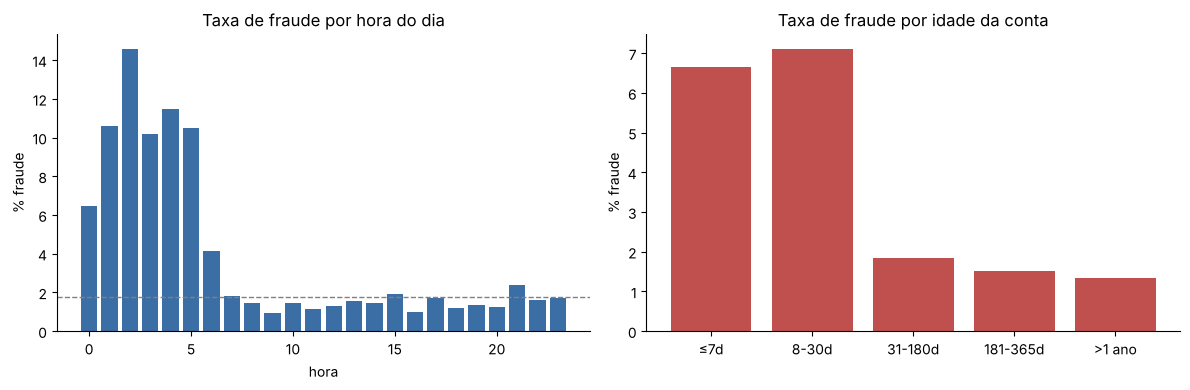

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
por_hora = df.groupby("hora").fraude.mean() * 100
ax[0].bar(por_hora.index, por_hora.values, color="#3B6EA5")
ax[0].axhline(df.fraude.mean() * 100, ls="--", c="gray", lw=1)
ax[0].set(title="Taxa de fraude por hora do dia", xlabel="hora", ylabel="% fraude")

idade = pd.cut(df.idade_conta_dias, [-1, 7, 30, 180, 365, 10_000],
               labels=["≤7d", "8-30d", "31-180d", "181-365d", ">1 ano"])
t = df.groupby(idade, observed=True).fraude.mean() * 100
ax[1].bar(t.index.astype(str), t.values, color="#C0504D")
ax[1].set(title="Taxa de fraude por idade da conta", ylabel="% fraude")
plt.tight_layout(); plt.savefig(FIG / "fraude_hora_idade_conta.png", dpi=120); plt.show()

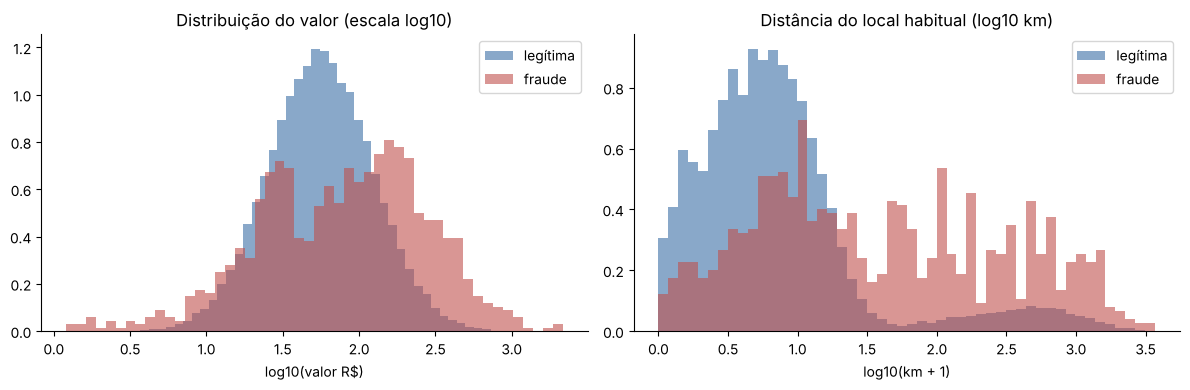

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for rotulo, cor in [(0, "#3B6EA5"), (1, "#C0504D")]:
    s = df.loc[df.fraude == rotulo, "valor"]
    ax[0].hist(np.log10(s), bins=50, alpha=.6, density=True, color=cor, label="fraude" if rotulo else "legítima")
ax[0].set(title="Distribuição do valor (escala log10)", xlabel="log10(valor R$)"); ax[0].legend()

for rotulo, cor in [(0, "#3B6EA5"), (1, "#C0504D")]:
    s = df.loc[df.fraude == rotulo, "distancia_casa_km"]
    ax[1].hist(np.log10(s + 1), bins=50, alpha=.6, density=True, color=cor, label="fraude" if rotulo else "legítima")
ax[1].set(title="Distância do local habitual (log10 km)", xlabel="log10(km + 1)"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "valor_distancia.png", dpi=120); plt.show()

In [9]:
# perfil de cada tipo de fraude versus transações legítimas
perfil = df.groupby("tipo_fraude").agg(
    transacoes=("transacao_id", "count"),
    ticket_mediano=("valor", "median"),
    pct_disp_novo=("dispositivo_novo", "mean"),
    pct_emulador=("emulador", "mean"),
    distancia_mediana_km=("distancia_casa_km", "median"),
    falhas_login_media=("falhas_login_24h", "mean"),
    idade_conta_mediana=("idade_conta_dias", "median"),
    tx_1h_media=("tx_ultima_1h", "mean"),
)
perfil

,transacoes,ticket_mediano,pct_disp_novo,pct_emulador,distancia_mediana_km,falhas_login_media,idade_conta_mediana,tx_1h_media
tipo_fraude,,,,,,,,
account_takeover,420,100.06,0.54,0.06,23.65,1.56,389.50,1.00
camuflada,150,83.66,0.08,0.00,4.95,0.16,385.50,1.01
card_testing,218,19.84,0.64,0.10,182.20,0.96,382.00,3.36
conta_falsa,260,177.09,0.50,0.25,21.70,0.44,22.50,1.00
nenhuma,58000,55.63,0.07,0.01,4.80,0.24,393.00,1.01


Cada tipo de fraude deixa uma "impressão digital" diferente:

| Tipo | Sinais mais fortes |
|---|---|
| **Account takeover** | valor alto, dispositivo novo, local distante, falhas de login, madrugada |
| **Card testing** | muitas transações de valor baixo em poucos minutos, canal web |
| **Conta falsa** | conta com poucos dias de vida, uso de emulador, ticket alto |

Isso indica que **uma única regra não pega todos os padrões**. É preciso combinar sinais.

## 4. Baseline: regras de negócio

In [10]:
# divisão temporal: treino nos primeiros 70 dias, teste nos últimos 20 (simula produção)
corte = df.data_hora.min() + pd.Timedelta(days=70)
treino, teste = df[df.data_hora < corte].copy(), df[df.data_hora >= corte].copy()

def regras(d):
    ato = (d.dispositivo_novo == 1) & ((d.distancia_casa_km >= 300) | (d.falhas_login_24h >= 3))
    card_testing = (d.tx_ultima_1h >= 3) & (d.valor <= 40)
    conta_falsa = (d.idade_conta_dias <= 30) & ((d.emulador == 1) | (d.dispositivo_novo == 1))
    return (ato | card_testing | conta_falsa).astype(int)

def avaliar(y, pred, valor, nome):
    tp = ((pred == 1) & (y == 1)); fp = ((pred == 1) & (y == 0))
    return pd.Series({
        "precisão": tp.sum() / max(pred.sum(), 1),
        "recall": tp.sum() / y.sum(),
        "% legítimas bloqueadas": fp.sum() / (y == 0).sum() * 100,
        "valor fraudado evitado (%)": valor[tp].sum() / valor[y == 1].sum() * 100,
    }, name=nome)

base_regras = avaliar(teste.fraude, regras(teste), teste.valor, "Regras")
base_regras.to_frame()

,Regras
precisão,0.48
recall,0.43
% legítimas bloqueadas,0.84
valor fraudado evitado (%),31.95


As regras são **simples e explicáveis**, mas rígidas. Elas deixam passar fraudes que fogem do padrão exato,
por exemplo um *account takeover* feito a partir de um dispositivo já conhecido.

## 5. Modelo de machine learning

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

def features(d):
    X = pd.DataFrame({
        "log_valor": np.log1p(d.valor),
        "dispositivo_novo": d.dispositivo_novo,
        "log_idade_disp": np.log1p(d.idade_dispositivo_dias),
        "emulador": d.emulador,
        "log_distancia": np.log1p(d.distancia_casa_km),
        "falhas_login_24h": d.falhas_login_24h,
        "log_idade_conta": np.log1p(d.idade_conta_dias),
        "tx_ultima_1h": d.tx_ultima_1h,
        "min_desde_ultima": d.min_desde_ultima.fillna(10_000).clip(upper=10_000),
        "madrugada": d.hora.between(0, 5).astype(int),
        "canal_web": (d.canal == "web").astype(int),
    })
    return X.join(pd.get_dummies(d.categoria, prefix="cat", dtype=int))

Xtr, Xte = features(treino), features(teste).reindex(columns=features(treino).columns, fill_value=0)
ytr, yte = treino.fraude, teste.fraude

modelos = {
    "Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42),
}
scores = {}
for nome, m in modelos.items():
    m.fit(Xtr, ytr)
    scores[nome] = m.predict_proba(Xte)[:, 1]

pd.DataFrame({nome: {"ROC-AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s)}
              for nome, s in scores.items()}).T

,ROC-AUC,PR-AUC
Regressão logística,0.93,0.65
Gradient boosting,0.94,0.79


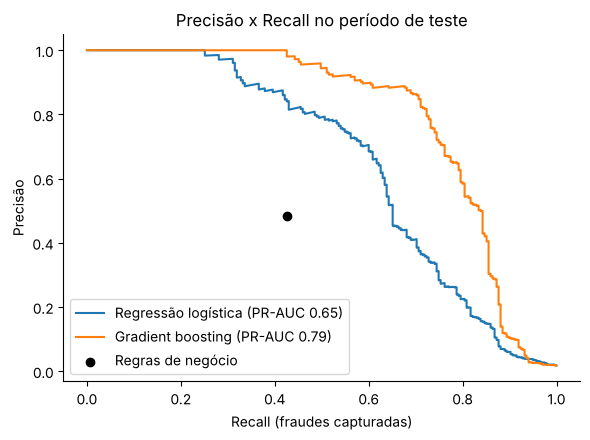

In [12]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for nome, s in scores.items():
    p, r, _ = precision_recall_curve(yte, s)
    ax.plot(r, p, label=f"{nome} (PR-AUC {average_precision_score(yte, s):.2f})")
ax.scatter(base_regras["recall"], base_regras["precisão"], c="black", zorder=5, label="Regras de negócio")
ax.set(xlabel="Recall (fraudes capturadas)", ylabel="Precisão", title="Precisão x Recall no período de teste")
ax.legend(loc="lower left"); plt.tight_layout(); plt.savefig(FIG / "precisao_recall.png", dpi=120); plt.show()

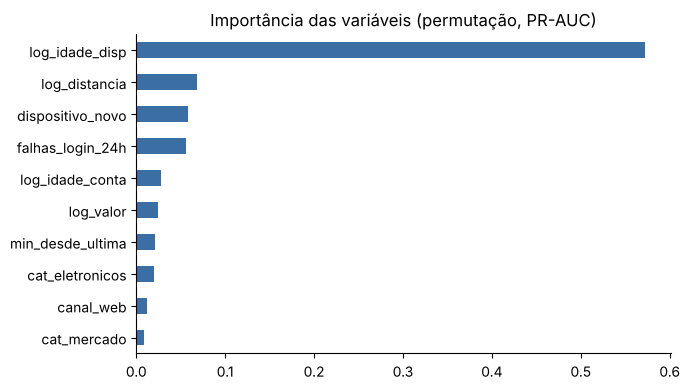

In [13]:
from sklearn.inspection import permutation_importance
gb = modelos["Gradient boosting"]
imp = permutation_importance(gb, Xte, yte, scoring="average_precision", n_repeats=5, random_state=42)
importancia = pd.Series(imp.importances_mean, index=Xte.columns).sort_values().tail(10)
importancia.plot.barh(color="#3B6EA5", figsize=(7, 4), title="Importância das variáveis (permutação, PR-AUC)")
plt.tight_layout(); plt.savefig(FIG / "importancia_variaveis.png", dpi=120); plt.show()

## 6. Escolha do ponto de corte pelo custo para o negócio

Um modelo devolve uma probabilidade. A decisão de **onde cortar** é de negócio. Premissas usadas:
- **Fraude aprovada:** perde-se o valor da transação.
- **Legítima bloqueada:** custo de atrito de **R$ 10** (atendimento e risco de perder o cliente). Essa é uma premissa que deve ser validada com a área.

In [14]:
CUSTO_FP = 10
s = scores["Gradient boosting"]
linhas = []
for corte_prob in np.linspace(0.005, 0.95, 190):
    pred = (s >= corte_prob).astype(int)
    tp = (pred == 1) & (yte == 1); fp = (pred == 1) & (yte == 0); fn = (pred == 0) & (yte == 1)
    linhas.append({"corte": corte_prob,
                   "custo_total": teste.valor[fn].sum() + fp.sum() * CUSTO_FP,
                   "precisão": tp.sum() / max(pred.sum(), 1), "recall": tp.sum() / yte.sum(),
                   "% legítimas bloqueadas": fp.sum() / (yte == 0).sum() * 100})
curva = pd.DataFrame(linhas)
melhor = curva.loc[curva.custo_total.idxmin()]

pred_reg = regras(teste)
custo_regras = teste.valor[(pred_reg == 0) & (yte == 1)].sum() + ((pred_reg == 1) & (yte == 0)).sum() * CUSTO_FP
custo_sem_nada = teste.valor[yte == 1].sum()

resumo = pd.DataFrame({
    "custo (R$)": [custo_sem_nada, custo_regras, melhor.custo_total],
}, index=["Sem prevenção", "Regras de negócio", f"Modelo (corte {melhor.corte:.2f})"])
resumo["economia vs. sem prevenção (%)"] = (1 - resumo["custo (R$)"] / custo_sem_nada) * 100
print(f"Melhor corte: {melhor.corte:.2f} | precisão {melhor['precisão']:.0%} | recall {melhor.recall:.0%} | "
      f"legítimas bloqueadas {melhor['% legítimas bloqueadas']:.2f}%")
resumo

Melhor corte: 0.12 | precisão 65% | recall 79% | legítimas bloqueadas 0.79%


,custo (R$),economia vs. sem prevenção (%)
Sem prevenção,"35,507.49",0.00
Regras de negócio,"25,232.64",28.94
Modelo (corte 0.12),"6,804.66",80.84


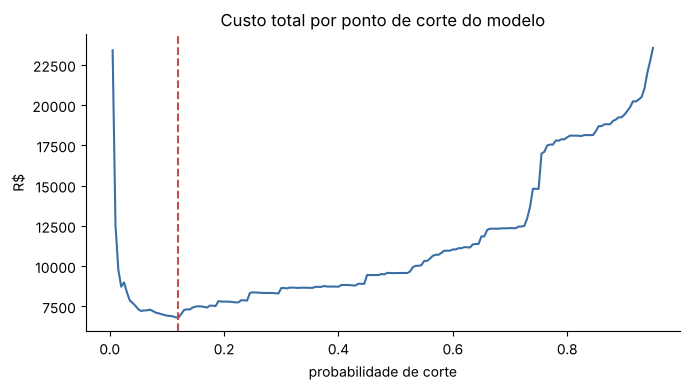

In [15]:
ax = curva.plot(x="corte", y="custo_total", legend=False, color="#3B6EA5", figsize=(7, 4))
ax.axvline(melhor.corte, ls="--", c="#C0504D")
ax.set(title="Custo total por ponto de corte do modelo", xlabel="probabilidade de corte", ylabel="R$")
plt.tight_layout(); plt.savefig(FIG / "custo_por_corte.png", dpi=120); plt.show()

In [16]:
# quais fraudes o modelo ainda deixa passar?
teste["score"] = s
teste["bloqueada"] = (s >= melhor.corte).astype(int)
(teste[teste.fraude == 1].groupby("tipo_fraude").bloqueada.mean() * 100).rename("% capturada").to_frame()

,% capturada
tipo_fraude,
account_takeover,85.56
camuflada,0.00
card_testing,94.55
conta_falsa,100.00


## 7. Conclusões e recomendações

1. **Combinar sinais funciona melhor do que regras isoladas.** O modelo supera as regras em PR-AUC e no custo total, porque
   pondera juntos dispositivo, localização, velocidade e idade da conta.
2. **Os sinais de dispositivo e localização são os mais fortes.** Dispositivo novo, emulador e distância do local habitual
   aparecem no topo da importância, junto com a velocidade de transações.
3. **O ponto de corte é uma decisão de negócio.** Com a premissa de R$ 10 por bloqueio indevido, o corte ótimo bloqueia uma
   fração pequena das transações legítimas e evita a maior parte do valor fraudado. Se o atrito custar mais, o corte sobe.
4. **Próximos passos sugeridos:**
   - adotar regras de alta precisão (rajadas de *card testing*) como bloqueio direto e usar o modelo como score para revisão ou autenticação extra;
   - monitorar a deriva dos sinais semanalmente, porque fraudadores mudam de padrão;
   - validar o custo de atrito com Produto e Customer Success;
   - tratar as fraudes "camufladas" (sem sinais de dispositivo ou localização) com outras fontes, como biometria comportamental,
     histórico de contestações e análise de rede entre contas. Nenhum modelo baseado só nesses sinais vai capturá-las.

*Limitação:* os dados são sintéticos. A metodologia (EDA, regras, validação temporal e custo) é o que se transfere para dados reais.